# 02 — Tạo crop tiền giấy

Mỗi dòng trong `DATA_RAW/metadata/raw_images.csv` tạo một crop. Hộp YOLO dùng tọa độ `xywh` chuẩn hóa; polygon dùng hộp ngoài của các điểm. Mở rộng 20% chiều rộng và chiều cao của hộp ở mỗi phía, rồi chặn tại biên ảnh. Ảnh crop giữ nguyên kích thước, lưu PNG RGB không mất dữ liệu.

`source_image_path` và `source_label_path` trong CSV kết quả tính từ `DATA_RAW`; `crop_path` tính từ `DATA_CROP`.

In [1]:
from pathlib import Path
import math
import pandas as pd
from PIL import Image

cwd = Path.cwd().resolve()
root = cwd if (cwd / "DATA_RAW").is_dir() else cwd.parents[1]
data_raw = root / "DATA_RAW"
data_crop = root / "DATA_CROP"
input_csv = data_raw / "metadata" / "raw_images.csv"
output_csv = data_crop / "metadata" / "crop_images.csv"
data_crop.mkdir(parents=True, exist_ok=True)
output_csv.parent.mkdir(parents=True, exist_ok=True)
images = pd.read_csv(input_csv, dtype=str).fillna("")
denominations = ["10000", "20000", "50000", "100000", "200000", "500000"]
sources = list(images["dataset_id"].drop_duplicates())


In [2]:
crop_counts = {source: {denomination: 0 for denomination in denominations} for source in sources}
metadata_rows = []
preview_rows = {}

for row in images.to_dict("records"):
    source = row["dataset_id"]
    denomination = row["denomination"]
    parts = row["annotation_raw"].split()
    values = list(map(float, parts[1:]))

    if len(parts) == 5:
        x_center, y_center, box_width, box_height = values
        x_min, y_min = x_center - box_width / 2, y_center - box_height / 2
        x_max, y_max = x_center + box_width / 2, y_center + box_height / 2
        annotation_type = "bbox"
    else:
        x_points, y_points = values[0::2], values[1::2]
        x_min, x_max = min(x_points), max(x_points)
        y_min, y_max = min(y_points), max(y_points)
        x_center, y_center = (x_min + x_max) / 2, (y_min + y_max) / 2
        box_width, box_height = x_max - x_min, y_max - y_min
        annotation_type = "polygon"

    source_path = data_raw / row["image_path"]
    with Image.open(source_path) as source_image:
        image = source_image.convert("RGB")
    width, height = image.size
    left = max(0, math.floor(max(0, x_min) * width - 0.2 * (x_max - x_min) * width))
    top = max(0, math.floor(max(0, y_min) * height - 0.2 * (y_max - y_min) * height))
    right = min(width, math.ceil(min(1, x_max) * width + 0.2 * (x_max - x_min) * width))
    bottom = min(height, math.ceil(min(1, y_max) * height + 0.2 * (y_max - y_min) * height))
    crop = image.crop((left, top, right, bottom))

    crop_counts[source][denomination] += 1
    crop_name = f"{source}_{denomination}_{crop_counts[source][denomination]:04d}.png"
    crop_folder = data_crop / denomination
    crop_folder.mkdir(parents=True, exist_ok=True)
    crop_path = crop_folder / crop_name
    crop.save(crop_path, format="PNG", compress_level=1)
    crop_width, crop_height = crop.size

    metadata_rows.append({
        "dataset_id": source,
        "source_rel_path": row["source_rel_path"],
        "source_image_path": row["image_path"],
        "source_label_path": row["label_path"],
        "class_id": row["class_id"],
        "class_name": row["class_name"],
        "denomination": denomination,
        "annotation_type": annotation_type,
        "annotation_raw": row["annotation_raw"],
        "crop_path": crop_path.relative_to(data_crop).as_posix(),
        "crop_width": crop_width,
        "crop_height": crop_height,
    })

    if source not in preview_rows or (source == "currency_v6" and annotation_type == "polygon" and preview_rows[source]["annotation_type"] != "polygon"):
        preview_rows[source] = {"row": row, "annotation_type": annotation_type, "crop_path": crop_path}

crop_metadata = pd.DataFrame(metadata_rows)
crop_metadata.to_csv(output_csv, index=False, encoding="utf-8-sig")
count_table = pd.DataFrame.from_dict(crop_counts, orient="index", columns=denominations)
count_table.index.name = "source"
from IPython.display import display
display(count_table)


,10000,20000,50000,100000,200000,500000
source,,,,,,
banknotes_v2,436,227,239,471,359,365
money_v1,1237,1036,1021,1222,1664,1108
blindtrix_v1,893,880,717,678,881,879
currency_v6,329,235,87,44,247,356


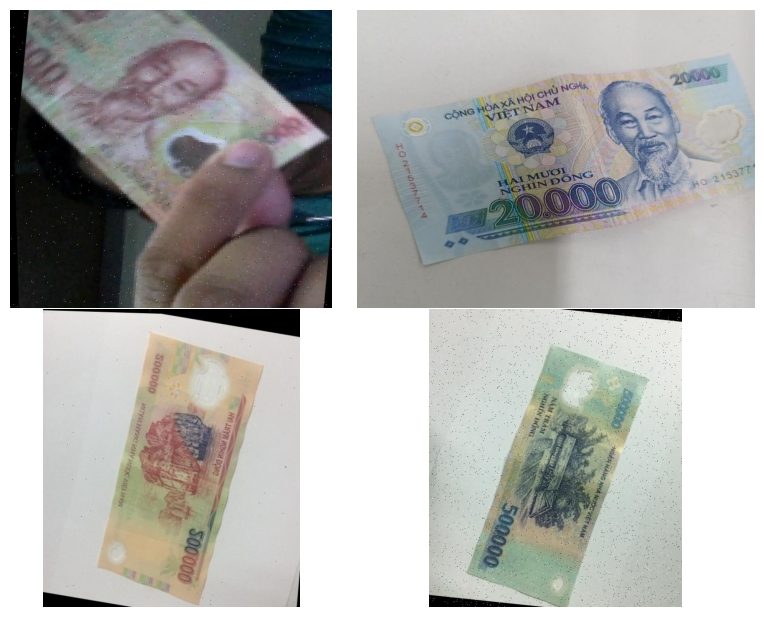

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(8, 6))
for ax, source in zip(axes.flat, sources):
    with Image.open(preview_rows[source]["crop_path"]) as crop:
        ax.imshow(crop.copy())
    ax.axis("off")
plt.tight_layout(pad=0.1)
plt.show()
